# T11 · Graphiques pédagogiques — DL/RL appliqués à la cybersécurité

Visualisations des concepts clés du module. Chaque figure illustre un point
théorique des notebooks T01–T09. En Colab, les graphiques s'affichent
**inline** ; chaque figure est aussi sauvegardée en PNG dans `outputs/`
(`dpi=120`).

| Figure | Concept | Notebook de référence |
|---|---|---|
| 1 | Frontière de décision (XOR) | T01 · P1 |
| 2 | Vanishing gradients | T02 · P2 |
| 3 | Descente de gradient & pas | T01 · P4 |
| 4 | Sur-apprentissage & capacité | T02 · P5 |
| 5 | Cartographies de caractères CNN | T04 · P5 |
| 6 | Porte d'oubli LSTM | T05 · P3 |
| 7 | Score d'anomalie & ROC | T06 · P4 |
| 8 | Convergence Q-Learning | T07 · P5 |

## 📌 Bloc 0 — Environnement & imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True, linewidth=100)
plt.rcParams['figure.figsize'] = (8, 5)
print("Matplotlib pret.")

Matplotlib pret.


## Figure 1 · Frontière de décision du perceptron (XOR)

Un MLP 2→4→1 (cachée $\tanh$, sortie sigmoïde) entraîné au gradient descend
sur le XOR — **impossible** pour un perceptron à une couche (non séparable
linéairement, T01 · P1). En bleu « classe 0 », en rouge « classe 1 » ;
la ligne noire est la frontière $P=0.5$ tracée par le réseau appris.

Figure 1 : prob. reseau = [0.022 0.956 0.964 0.046], exactitude = 100%


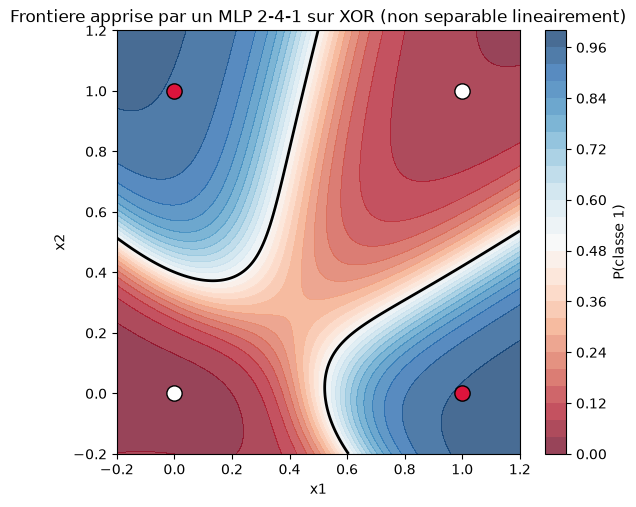

In [2]:
# Figure 1 : frontiere de decision XOR (MLP 2-4-1 numpy)
rng = np.random.default_rng(42)                  # rng isole pour cette cellule
Xxor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], float)
yxor = np.array([[0], [1], [1], [0]], float)
W1 = rng.normal(0, 1, (2, 4)); b1 = np.zeros((1, 4))
W2 = rng.normal(0, 1, (4, 1)); b2 = np.zeros((1, 1))
sg = lambda z: 1.0 / (1.0 + np.exp(-z))
lr = 0.5
for it in range(3000):
    Z1 = Xxor @ W1 + b1; A1 = np.tanh(Z1)
    Yh = sg(A1 @ W2 + b2)
    dZ2 = (Yh - yxor) * Yh * (1 - Yh) / 4
    dA1 = dZ2 @ W2.T; dZ1 = dA1 * (1 - A1 ** 2)
    W2 -= lr * (A1.T @ dZ2); b2 -= lr * dZ2.sum(axis=0)
    W1 -= lr * (Xxor.T @ dZ1); b1 -= lr * dZ1.sum(axis=0)
Yh = sg(np.tanh(Xxor @ W1 + b1) @ W2 + b2)
pred = (Yh > 0.5).astype(int)
acc = (pred == yxor.astype(int)).mean()
print(f"Figure 1 : prob. reseau = {Yh.ravel().round(3)}, exactitude = {acc:.0%}")
assert acc == 1.0
g = np.linspace(-0.2, 1.2, 240)
G1, G2 = np.meshgrid(g, g)
pts = np.stack([G1.ravel(), G2.ravel()], axis=1)
Zgrid = sg(np.tanh(pts @ W1 + b1) @ W2 + b2).reshape(G1.shape)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
cs = ax.contourf(G1, G2, Zgrid, levels=30, cmap='RdBu', alpha=0.75)
ax.contour(G1, G2, Zgrid, levels=[0.5], colors='k', linewidths=2)
for (a, b), lab in zip(Xxor, yxor.ravel()):
    ax.plot(a, b, 'o', ms=11, color='white' if lab == 0 else 'crimson',
            mec='k', zorder=5)
ax.set_title("Frontiere apprise par un MLP 2-4-1 sur XOR (non separable lineairement)")
ax.set_xlabel('x1'); ax.set_ylabel('x2')
fig.colorbar(cs, ax=ax, label='P(classe 1)')
fig.savefig('../outputs/fig01_perceptron_frontier.png', dpi=120)
plt.show()
plt.close(fig)

## Figure 2 · Vanishing gradients (réseau sigmoïde profond)

MLP 20→30×9→1 à sigmoïdes (10 couches), rétropropagation complète : on trace la
**norme du gradient** $\lVert\partial L/\partial W^{(\ell)}\rVert_F$ par couche (échelle
log). Chaque traversée de sigmoïde multiplie le signal par $\sigma'\le 0.25$ :
la couche 1 reçoit des gradients **des milliers de fois** plus faibles que la
dernière — d'où Xavier/He, ReLU et normalisation (T02 · P2–P4).

Figure 2 : ||dL/dW|| par couche (1 -> 10) = [  0.026   0.311   0.848   2.615   5.675  10.535  19.825  49.518  80.485 163.949]
  ratio couche1/couche10 = 1.56e-04


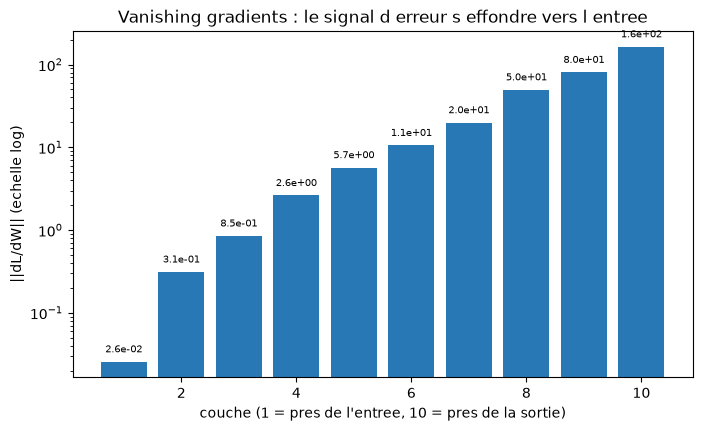

In [3]:
# Figure 2 : vanishing gradients — norme du gradient par couche
rng = np.random.default_rng(1)                   # rng isole pour cette cellule
sizes = [20] + [30] * 9 + [1]
sgm = lambda z: 1.0 / (1.0 + np.exp(-z))
Ws = [rng.normal(0, 0.5, (sizes[i], sizes[i + 1])) for i in range(len(sizes) - 1)]
x = rng.normal(0, 1, (500, sizes[0]))
acts = [x]
for W in Ws:
    acts.append(sgm(acts[-1] @ W))
d = (acts[-1] - 1.0) * acts[-1] * (1 - acts[-1])  # perte MSE cible=1
gnorms = []
for i in range(len(Ws) - 1, -1, -1):
    gnorms.append(np.linalg.norm(acts[i].T @ d))
    if i > 0:
        d = (d @ Ws[i].T) * acts[i] * (1 - acts[i])
gnorms = np.array(gnorms[::-1])
print(f"Figure 2 : ||dL/dW|| par couche (1 -> 10) = {gnorms.round(3)}")
print(f"  ratio couche1/couche10 = {gnorms[0]/gnorms[-1]:.2e}")
assert np.all(np.diff(gnorms) > 0)                # strictement croissant vers la sortie
assert gnorms[0] < gnorms[-1] / 100               # effondrement a l'avant
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(range(1, 11), gnorms, color='#2878b5')
ax.set_yscale('log')
ax.set_xlabel('couche (1 = pres de l\'entree, 10 = pres de la sortie)')
ax.set_ylabel('||dL/dW|| (echelle log)')
ax.set_title('Vanishing gradients : le signal d erreur s effondre vers l entree')
for i, gv in enumerate(gnorms):
    ax.text(i + 1, gv * 1.3, f'{gv:.1e}', ha='center', fontsize=7)
fig.savefig('../outputs/fig02_vanishing_gradients.png', dpi=120)
plt.show()
plt.close(fig)

## Figure 2 bis ? Non : Figure 3 · Descente de gradient : trois pas d'apprentissage

Sur $f(x)=2.5x^2$ (courbure $H=5$) depuis $x_0=3$, on trace la perte (échelle
log) pour $\alpha\in\{0.001,\,0.01,\,0.3\}$. Le **pas** $\alpha$ est l'hyperparamètre le
plus sensible : trop petit → convergence en 100 itérations à peine entamée ;
trop grand → oscillations (ici encore amorties car $\alpha H<2$ ; au-delà de
$0.4$ la descente **diverge**, T01 · P4 / T03 · P5).

Figure 3 : lr=0.001 -> perte finale = 8.26e+00
Figure 3 : lr=0.01 -> perte finale = 7.89e-04
Figure 3 : lr=0.3 -> perte finale = 1.40e-59


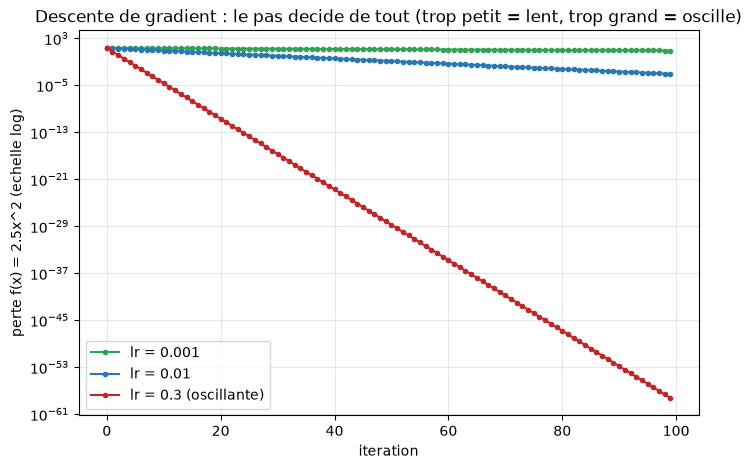

In [4]:
# Figure 3 : courbes de perte GD pour 3 pas d'apprentissage
f3 = lambda xx: 2.5 * xx ** 2
df3 = lambda xx: 5.0 * xx
curves = {}
for lrc in [0.001, 0.01, 0.3]:
    xt = 3.0
    hist = []
    for _ in range(100):
        hist.append(f3(xt))
        xt = xt - lrc * df3(xt)
    curves[lrc] = np.array(hist)
    print(f"Figure 3 : lr={lrc} -> perte finale = {f3(xt):.2e}")
assert curves[0.001][-1] > curves[0.01][-1] > curves[0.3][-1]
# lr=0.3 : facteur (1-1.5) = -0.5 -> decroissance OSCILEE (signe de x alterne)
xs_osc = [3.0]
for _ in range(6):
    xs_osc.append(xs_osc[-1] - 0.3 * df3(xs_osc[-1]))
assert all(xs_osc[i] * xs_osc[i + 1] < 0 for i in range(1, 5))  # oscillation installee
fig, ax = plt.subplots(figsize=(8, 5))
cols = {0.001: '#31a354', 0.01: '#2878b5', 0.3: '#c12526'}
for lrc, hist in curves.items():
    ax.plot(hist, 'o-', ms=3, lw=1.5, color=cols[lrc],
            label=f'lr = {lrc}' + (' (oscillante)' if lrc == 0.3 else ''))
ax.set_yscale('log')
ax.set_xlabel('iteration'); ax.set_ylabel('perte f(x) = 2.5x^2 (echelle log)')
ax.set_title('Descente de gradient : le pas decide de tout (trop petit = lent, trop grand = oscille)')
ax.legend()
ax.grid(alpha=0.3, which='both')
fig.savefig('../outputs/fig03_gd_learning_rates.png', dpi=120)
plt.show()
plt.close(fig)

## Figure 4 · Sur-apprentissage : courbes train/val selon la capacité

Régression polynomiale sur $\sin(\pi x/2)$ bruité, 18 points d'entraînement.
En **log MSE** : l'erreur de train ne fait que décroître avec le degré, mais
l'erreur de validation remonte en flèche au-delà du degré optimal — le modèle
mémorise le bruit (T02 · P5). Garde-fou cyber : un détecteur sur-appris sur une
campagne d'attaques donnée aveugle sur la suivante (drift, T09 · P2).

Figure 4 : meilleur degre en validation = 7
  MSE train : 0.148 -> 0.005 (ne fait que baisser)
  MSE val   : 0.416 -> 0.090 (deg 7) -> 0.9 (explosion)


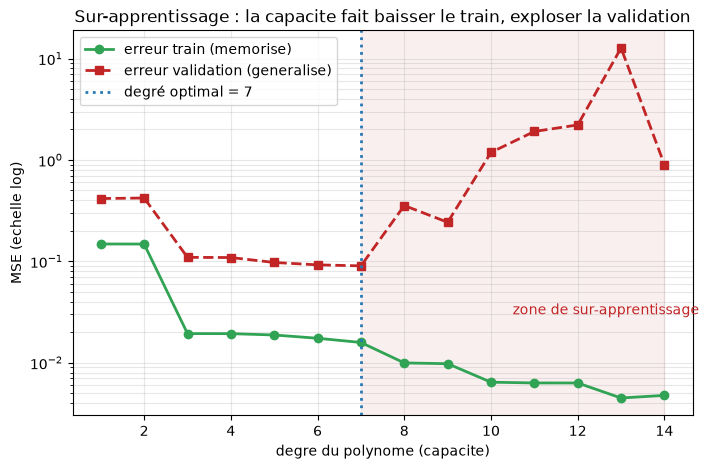

In [5]:
# Figure 4 : MSE train/val selon le degre du polynome (capacite)
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
rng = np.random.default_rng(0)                   # rng isole pour cette cellule
xtr = rng.uniform(-2, 2, 18); ytr = np.sin(np.pi * xtr / 2) + rng.normal(0, 0.25, 18)
xva = rng.uniform(-2, 2, 120); yva = np.sin(np.pi * xva / 2) + rng.normal(0, 0.25, 120)
degs = list(range(1, 15))
tr_e, va_e = [], []
for deg in degs:
    m = make_pipeline(PolynomialFeatures(deg), StandardScaler(), LinearRegression())
    m.fit(xtr.reshape(-1, 1), ytr)
    tr_e.append(np.mean((m.predict(xtr.reshape(-1, 1)) - ytr) ** 2))
    va_e.append(np.mean((m.predict(xva.reshape(-1, 1)) - yva) ** 2))
tr_e = np.array(tr_e); va_e = np.array(va_e)
best_deg = int(va_e.argmin()) + 1
print(f"Figure 4 : meilleur degre en validation = {best_deg}")
print(f"  MSE train : {tr_e[0]:.3f} -> {tr_e[-1]:.3f} (ne fait que baisser)")
print(f"  MSE val   : {va_e[0]:.3f} -> {va_e.min():.3f} (deg {best_deg}) -> {va_e[-1]:.1f} (explosion)")
assert 2 <= best_deg <= 9
assert va_e[-1] > 5 * va_e.min()                   # sur-apprentissage net en fin de courbe
assert tr_e[-1] < tr_e[0]                          # train monotone descendant
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(degs, tr_e, 'o-', color='#31a354', lw=2, label='erreur train (memorise)')
ax.plot(degs, va_e, 's--', color='#c12526', lw=2, label='erreur validation (generalise)')
ax.axvline(best_deg, color='#2878b5', ls=':', lw=2, label=f'degré optimal = {best_deg}')
ax.axvspan(best_deg, 14, color='#c12526', alpha=0.07)
ax.text(10.5, 0.03, 'zone de sur-apprentissage', color='#c12526', fontsize=10)
ax.set_yscale('log'); ax.set_xlabel('degre du polynome (capacite)'); ax.set_ylabel('MSE (echelle log)')
ax.set_title('Sur-apprentissage : la capacite fait baisser le train, exploser la validation')
ax.legend(); ax.grid(alpha=0.3, which='both')
fig.savefig('../outputs/fig04_overfitting_capacity.png', dpi=120)
plt.show()
plt.close(fig)

## Figure 5 · Cartographies de caractères d'un CNN

Entrée 24×24 (carré synthétique + bruit) convoluée par 4 filtres 3×3 figés
(identité, détection d'arêtes horizontales / verticales / diagonale). Une
**cartographie de caractères** signale où le motif recherché apparaît — c'est
le mécanisme qui repère une signature dans un bloc de bytes de malware
(T04 · P5, interprétabilité).

Figure 5 : filtre identite        max|reponse| = 1.13
Figure 5 : filtre aretes horiz.   max|reponse| = 3.11
Figure 5 : filtre aretes vert.    max|reponse| = 3.31
Figure 5 : filtre diagonale       max|reponse| = 6.23


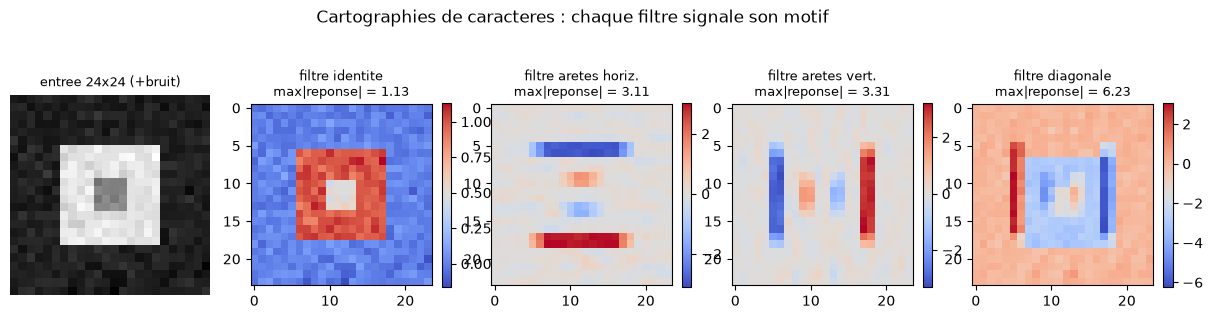

In [6]:
# Figure 5 : cartographies de caracteres CNN (filtres d'aretes)
from scipy.signal import convolve2d
rng = np.random.default_rng(5)                   # rng isole pour cette cellule
img = np.zeros((24, 24))
img[6:18, 6:18] = 1.0; img[10:14, 10:14] = 0.5
img_noisy = img + rng.normal(0, 0.05, (24, 24))
filters = {
    'identite': np.array([[0, 0, 0], [0, 1, 0], [0, 0, 0]], float),
    'aretes horiz.': np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], float),
    'aretes vert.': np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], float),
    'diagonale': np.array([[2, 0, -2], [1, -1, 0], [0, -1, -2]], float),
}
fig, axes = plt.subplots(1, 5, figsize=(15, 3.4))
axes[0].imshow(img_noisy, cmap='gray')
axes[0].set_title('entree 24x24 (+bruit)', fontsize=9)
for ax, (name, flt) in zip(axes[1:], filters.items()):
    fm = convolve2d(img_noisy, flt, mode='same')
    im = ax.imshow(fm, cmap='coolwarm')
    ax.set_title(f'filtre {name}\nmax|reponse| = {np.abs(fm).max():.2f}', fontsize=9)
    fig.colorbar(im, ax=ax, fraction=0.046)
    print(f"Figure 5 : filtre {name:15s} max|reponse| = {np.abs(fm).max():.2f}")
assert np.abs(convolve2d(img_noisy, filters['aretes horiz.'], mode='same')).max() > 2
assert np.abs(convolve2d(img_noisy, filters['diagonale'], mode='same')).max() > 2
axes[0].axis('off')
fig.suptitle('Cartographies de caracteres : chaque filtre signale son motif', y=1.04)
fig.savefig('../outputs/fig05_cnn_feature_maps.png', dpi=120)
plt.show()
plt.close(fig)

## Figure 6 · Porte d'oubli LSTM le long d'une séquence de logs

LSTM 8 unités, poids fixés par graine ; séquence de 30 « événements » : régime
normal ($t<15$) puis **pic d'exfiltration** ($t\ge15$, saut de la moyenne des
entrées). À gauche, la heatmap $f_t$ par unité ; à droite, sa moyenne. La porte
s'ouvre quand le régime change : la cellule **accepte de réécrire sa mémoire**
— exactement le comportement qui permet de séparer session normale et exfiltration
(T05 · P3, P6).

Figure 6 : f moyen avant le changement de regime = 0.499
  f moyen apres (exfiltration) = 0.790


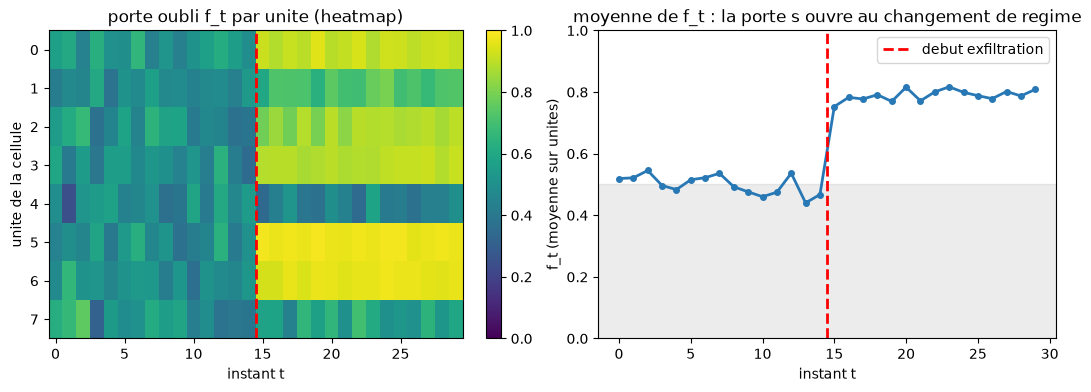

In [7]:
# Figure 6 : valeur de la porte d'oubli LSTM le long d'une sequence
rng = np.random.default_rng(9)                   # rng isole pour cette cellule
dh = 8
sgl = lambda z: 1.0 / (1.0 + np.exp(-z))
Wf = rng.normal(0, 1, (dh, 2 * dh)) / np.sqrt(2 * dh)
Wi = rng.normal(0, 1, (dh, 2 * dh)) / np.sqrt(2 * dh)
Wo = rng.normal(0, 1, (dh, 2 * dh)) / np.sqrt(2 * dh)
Wc = rng.normal(0, 1, (dh, 2 * dh)) / np.sqrt(2 * dh)
Wf[:, dh:] += np.eye(dh) * 0.8                   # tendance a conserver
bf = np.zeros(dh)
seq = np.vstack([rng.normal(0, 0.3, (15, dh)), rng.normal(1.8, 0.3, (15, dh))])
h = np.zeros(dh); c = np.zeros(dh)
Fmat = np.zeros((dh, 30))
for t in range(30):
    cat = np.concatenate([h, seq[t]])
    f = sgl(Wf @ cat + bf); i = sgl(Wi @ cat)
    gc = np.tanh(Wc @ cat); o = sgl(Wo @ cat)
    c = f * c + i * gc; h = o * np.tanh(c)
    Fmat[:, t] = f
fm = Fmat.mean(axis=0)
print(f"Figure 6 : f moyen avant le changement de regime = {fm[:15].mean():.3f}")
print(f"  f moyen apres (exfiltration) = {fm[15:].mean():.3f}")
assert np.all((Fmat >= 0) & (Fmat <= 1))         # sigmoide oblige
assert fm[15:].mean() - fm[:15].mean() > 0.1     # la porte s'ouvre au changement
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
im = axes[0].imshow(Fmat, aspect='auto', cmap='viridis', vmin=0, vmax=1)
axes[0].set_title('porte oubli f_t par unite (heatmap)')
axes[0].set_xlabel('instant t'); axes[0].set_ylabel('unite de la cellule')
axes[0].axvline(14.5, color='r', ls='--', lw=2)
fig.colorbar(im, ax=axes[0], fraction=0.046)
axes[1].plot(fm, 'o-', color='#2878b5', lw=2, ms=4)
axes[1].axvline(14.5, color='r', ls='--', lw=2, label='debut exfiltration')
axes[1].axhspan(0, 0.5, color='grey', alpha=0.15)
axes[1].set_title('moyenne de f_t : la porte s ouvre au changement de regime')
axes[1].set_xlabel('instant t'); axes[1].set_ylabel('f_t (moyenne sur unites)')
axes[1].set_ylim(0, 1); axes[1].legend()
fig.savefig('../outputs/fig06_lstm_forget_gate.png', dpi=120)
plt.show()
plt.close(fig)

## Figure 7 · Score d'anomalie (auto-encodeur) et ROC

Reconstruction par AE linéaire (PCA, goulot 1) sur des flux réseau synthétiques :
les flux **bénins** vivent près du sous-espace principal (erreur de
reconstruction faible), les **attaques** en sont loin (erreur élevée). La
courbe ROC sépare presque parfaitement les deux populations ; l'AUC est
annotée (T06 · P4–P6).

Figure 7 : erreur moyenne benignes = 0.005, attaques = 2.662
  AUC = 0.9988


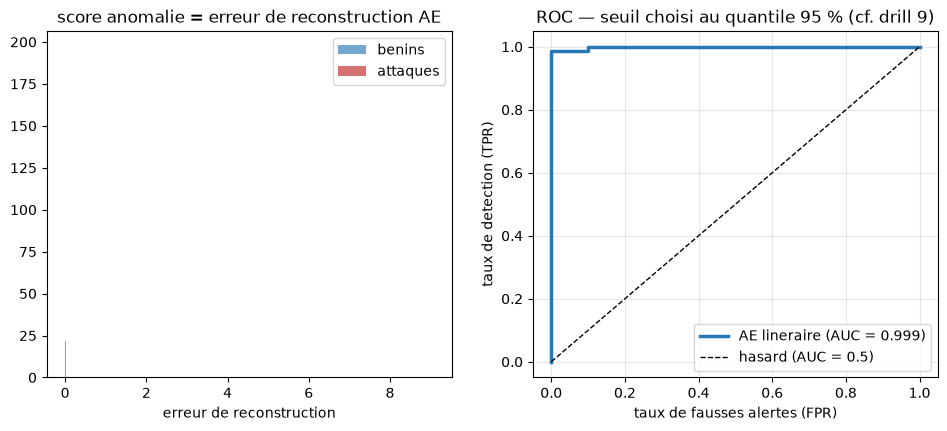

In [8]:
# Figure 7 : score de reconstruction AE + courbe ROC / AUC
from sklearn.metrics import roc_curve, auc
rng = np.random.default_rng(4)                   # rng isole pour cette cellule
base = rng.normal(size=(300, 1))
Xb = base @ np.array([[2.0, 1.0, 0.5]]) + rng.normal(0, 0.05, (300, 3))
Xc_ = Xb - Xb.mean(axis=0)
cov = Xc_.T @ Xc_ / len(Xc_)
lam, Vv = np.linalg.eigh(cov)
v1 = Vv[:, -1]
err_b = np.sum((Xc_ - np.outer(Xc_ @ v1, v1)) ** 2, axis=1)
Xa = Xc_[:80] + rng.normal(0, 1.2, (80, 3))      # attaques hors sous-espace
err_a = np.sum((Xa - np.outer(Xa @ v1, v1)) ** 2, axis=1)
print(f"Figure 7 : erreur moyenne benignes = {err_b.mean():.3f}, attaques = {err_a.mean():.3f}")
scores = np.concatenate([err_b, err_a])
labels = np.array([0] * len(err_b) + [1] * len(err_a))
fpr, tpr, _ = roc_curve(labels, scores)
auc_val = auc(fpr, tpr)
print(f"  AUC = {auc_val:.4f}")
assert err_a.mean() > 5 * err_b.mean()           # separation franchise des scores
assert auc_val >= 0.95
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5))
axes[0].hist(err_b, bins=30, alpha=0.65, label='benins', color='#2878b5', density=True)
axes[0].hist(err_a, bins=30, alpha=0.65, label='attaques', color='#c12526', density=True)
axes[0].set_title('score anomalie = erreur de reconstruction AE')
axes[0].set_xlabel('erreur de reconstruction'); axes[0].legend()
axes[1].plot(fpr, tpr, lw=2.5, color='#2878b5', label=f'AE lineraire (AUC = {auc_val:.3f})')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1, label='hasard (AUC = 0.5)')
axes[1].set_xlabel('taux de fausses alertes (FPR)'); axes[1].set_ylabel('taux de detection (TPR)')
axes[1].set_title('ROC — seuil choisi au quantile 95 % (cf. drill 9)')
axes[1].legend(loc='lower right'); axes[1].grid(alpha=0.3)
fig.savefig('../outputs/fig07_anomaly_roc.png', dpi=120)
plt.show()
plt.close(fig)

## Figure 8 · Q-Learning : retours vs stratégie d'exploration (ε)

Chaîne glissante 0→1→2→3→terminal (récompense +1, ε-greedy, $\alpha=0.5$,
$\gamma=0.9$, moyenne mobile sur 50 épisodes) pour trois réglages :
- **ε = 0.05** : converge très vite mais dépend de l'estimation initiale ;
- **ε = 0.9** : explore sans fin, retour plafonné par le bruit de l'exploration ;
- **ε décroissant 1.0→0.05** : la courbe en S classique — l'**épisode de
  convergence** (MA ≥ 90 % du meilleur régime) est annoté (T07 · P4–P5).

Figure 8 : eps = 0.05      premiere MA = 0.86, derniere MA = 0.83, politique gloutonne = [0 0 0 0]
Figure 8 : eps = 0.9       premiere MA = 0.24, derniere MA = 0.37, politique gloutonne = [0 0 0 0]
Figure 8 : eps décroissant premiere MA = 0.36, derniere MA = 0.81, politique gloutonne = [0 0 0 0]
  episode de convergence (MA >= 0.9 * meilleur) : 85


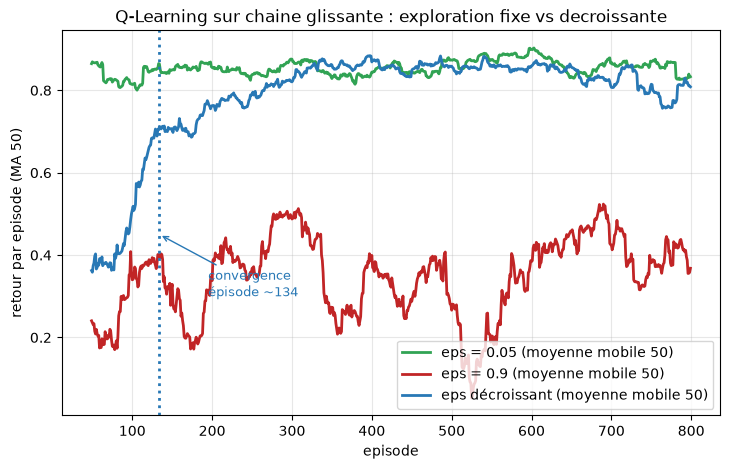

In [9]:
# Figure 8 : convergence Q-Learning pour trois regimes d'exploration
nS = 4
al, gam = 0.5, 0.9

def ql_run(eps_fn, seed, n_ep=800):
    rng = np.random.default_rng(seed)            # rng isole par execution
    Q = np.zeros((nS, 2)); returns = []
    for ep in range(n_ep):
        eps = eps_fn(ep)
        s = 0; R = 0.0
        for _ in range(60):
            a = int(rng.integers(0, 2)) if rng.random() < eps else int(Q[s].argmax())
            if a == 0:
                r_ = -0.01
                s2 = s + 1 if rng.random() < 0.6 else max(s - 1, 0)
            else:
                r_ = -0.05; s2 = s
            if s2 == nS:
                r_ = 1.0
            Q[s, a] += al * (r_ + (0.0 if s2 == nS else gam * Q[s2].max()) - Q[s, a])
            R += r_; s = s2
            if s == nS:
                break
        returns.append(R)
    return np.array(returns), Q

runs = {}
runs['eps = 0.05'] = ql_run(lambda ep: 0.05, 202)
runs['eps = 0.9'] = ql_run(lambda ep: 0.9, 101)
runs['eps décroissant'] = ql_run(lambda ep: max(0.05, 1.0 - ep / 300), 7)
for name, (rr, QQ) in runs.items():
    ma = np.convolve(rr, np.ones(50) / 50, 'valid')
    print(f"Figure 8 : {name:15s} premiere MA = {ma[0]:.2f}, derniere MA = {ma[-1]:.2f}, "
          f"politique gloutonne = {QQ.argmax(axis=1)}")
ma_decay = np.convolve(runs['eps décroissant'][0], np.ones(50) / 50, 'valid')
best = ma_decay[-50:].mean()
conv_ep = int(np.argmax(ma_decay >= 0.9 * best))
print(f"  episode de convergence (MA >= 0.9 * meilleur) : {conv_ep}")
assert (runs['eps décroissant'][1].argmax(axis=1) == 0).all()   # politique optimale = avancer
assert ma_decay[-1] > ma_decay[0] + 0.2           # apprentissage visible
assert 20 < conv_ep < 300                          # convergence au milieu du run
fig, ax = plt.subplots(figsize=(8.5, 5))
cols = {'eps = 0.05': '#31a354', 'eps = 0.9': '#c12526', 'eps décroissant': '#2878b5'}
for name, (rr, _) in runs.items():
    ma = np.convolve(rr, np.ones(50) / 50, 'valid')
    ax.plot(range(49, len(rr)), ma, lw=2, color=cols[name],
            label=f'{name} (moyenne mobile 50)')
ax.axvline(conv_ep + 49, color='#2878b5', ls=':', lw=2)
ax.annotate(f'convergence\népisode ~{conv_ep + 49}', xy=(conv_ep + 49, 0.45),
            xytext=(conv_ep + 110, 0.3), fontsize=9, color='#2878b5',
            arrowprops=dict(arrowstyle='->', color='#2878b5'))
ax.set_xlabel('episode'); ax.set_ylabel('retour par episode (MA 50)')
ax.set_title('Q-Learning sur chaine glissante : exploration fixe vs decroissante')
ax.legend(loc='lower right'); ax.grid(alpha=0.3)
fig.savefig('../outputs/fig08_qlearning_convergence.png', dpi=120)
plt.show()
plt.close(fig)

In [10]:
print("NB 11 — les 8 figures sont générées. ✅")

NB 11 — les 8 figures sont générées. ✅
